<a href="https://colab.research.google.com/github/w-olivine29/data-analysis/blob/main/%EC%98%A4%ED%94%88%EC%86%8C%EC%8A%A4_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D_13%EA%B0%95_%EC%8B%A4%EC%8A%B5_%EB%B0%98%EC%A0%95%ED%98%95_%EB%8D%B0%EC%9D%B4%ED%84%B0_%EB%B6%84%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13강 반정형 데이터 분석 : 게시판 글 데이터 활용

### 목표

방송통신대학교 학생 게시판의 글 제목을 수집하고 분석하여, 반정형 데이터의 수집부터 텍스트 분석까지 전체 과정을 실습

### 분석 프로세스 개요

1. 데이터 수집
  - selenium을 활용한 웹 페이지 접근
  - lxml을 이용한 HTML 파싱
  - 게시글 제목 추출

2. 텍스트 데이터 전처리
  - 정규식을 활용한 텍스트 정제
  - 형태소 분석을 통한 명사 추출

3. 키워드 분석
  - 단어 빈도 분석
  - 워드 클라우드 생성
  - 주요 키워드 추출

4. 텍스트 분류 및 시각화
  - LLM을 활용한 텍스트 분류
  - 분류 결과 시각화
  - 인사이트 도출


# 주의 : 런타임 GPU 로 설정 필요

In [10]:
# colab에서도 별도로 조그만 LLM을 돌릴 수 있음
# 그걸 위해서 별도의 라이브러리 설치가 필요한데, 그것을 도와주기 위한 VLLM이라는 것을 먼저 설치

# LLM 처리를 위한 VLLM 설치 (오래걸리는 작업이므로 미리 실행!)
# !pip install vllm==0.9.0 transformers==4.52.4 (실습 코드에서 제공된 코드이나 버전 문제가 있음)

!pip install vllm transformers
# 필요 시 세션 재시작

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 MB 61.5 MB/s  0:00:04
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 89.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.7/33.7 MB 105.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 96.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 87.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 59.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 53.9 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 MB 53.4 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 782.6/782.6 kB 48.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 92.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.2/43.2 MB 54.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 37.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 MB 49.6 MB/s  0:00:01
   ━━━━━━━━━━━━

In [1]:
# 한글 처리를 위한 matplotlib 설정 (1)

!sudo apt-get install -y fonts-nanum
!sudo fc-cache –fv
!rm ~/.cache/matplotlib -rf

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 2s (5,158 kB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 127324 files and

- 런타임 -> 세션 다시 시작

In [1]:
# 한글 처리를 위한 matplotlib 설정 (2)

import matplotlib.pyplot as plt
plt.rc('font', family='NanumBarunGothic')

# 1. 데이터 수집 및 전처리

## 13-1 웹 스크래핑 라이브러리 설치

In [2]:
!pip install google-colab-selenium lxml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 62.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 89.1 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [google-colab-selenium]


## 13-2 웹 스크래핑 함수 정의 및 실행

In [3]:
import google_colab_selenium as gs
from lxml import html

## URL로부터 페이지 내용 가져오기
def get_page(driver, url): # selenium 드라이버를 인수로 받을 것임 (가상의 웹 브라우저라고 생각하면 된다)
    # url 페이지로 이동
    driver.get(url)

    # 해당 페이지의 html을 page_content로 저장
    page_content = driver.page_source

    # page_content를 lxml의 html 객체로 변환하고 tree로 저장
    tree = html.fromstring(page_content)

    return tree

## HTML 트리에서 제목들을 추출 (직접 원하는 웹페이지에서 개발자도구를 통해 html 구조를 파악해야함)
def extract_titles(tree):
    ## td-subject를 클래스로 가지는 td 태그 > a태그 > string > text() 을 xpath로 구하고 titles로 저장
    titles = tree.xpath('//td[@class = "td-subject"]/a/strong/text( )')

    return titles

## 제목 목록 출력
def print_titles(titles):
    for title in titles:
        print(title)

## Chrome 드라이버 초기화
driver = gs.Chrome()

## 컴퓨터과학과 게시판 첫번째 페이지 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
tree = get_page(driver, board_url)
titles = extract_titles(tree)
print_titles(titles)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

[한국능률협회] 미래내일 프로젝트 참여자 모집
SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!
[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 헬스케어
[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청
2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집


## 13-3 다중 페이지 데이터 수집 및 데이터프레임 생성

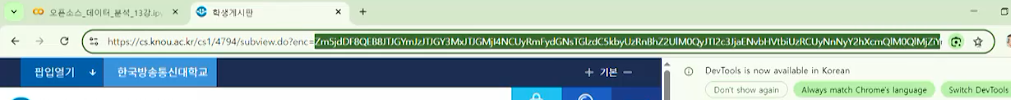



다음 페이지로도 이동하려는데, url를 보면 page가 2라고 경로나 파람으로 돼있지 않고, 무언가 암호화된듯한 문자로 돼있음

-> url을 통해서 페이지를 바꿀 수가 없고, 페이지에서 제공되는 버튼을 클릭해야 다음페이지로 넘어가는 방식인 상황

-> 셀레늄을 이용하여 마우스 커서를 페이지 이동 버튼 엘리멘트를 선택하고 클릭하는 행동을 가상 웹 브라우저 내에서 모사를 하여 다음 페이지로 넘어가야함

In [4]:
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
import pandas as pd




## 다음 페이지로 이동하고 tree 정보 반환
def move_to_next_page(driver):
    # _listNext 클래스를 기준으로 엘리먼트 선택
    next_page_link = driver.find_element(By.CLASS_NAME, '_listNext')

    # 가져온 엘리먼트의 사용 여부에 따라 동작
    if next_page_link and next_page_link.is_enabled():

        # 다음 페이지 버튼 클릭 (가상 웹 브라우저에서 해당 버튼을 클릭)
        next_page_link.click( )

        # 클릭한 다음에 그 다음 페이지가 로딩이 잘 되는지 확인하는 일종의 유틸리티 구문
        # board-table 은 게시판 전체의 클래스이며 이것이 보이기 전까지만 기다리는 것
        WebDriverWait(driver, 10).until(
            EC.presence_of_element_located((By.CLASS_NAME, "board-table"))
        )
        page_content = driver.page_source
        tree = html.fromstring(page_content)
        return tree
    else:
        return None

## 여러 페이지에서 게시물 제목 가져오기
def get_board_titles(url, pages, verbose=False): # verbose 는 디버깅할 때 쓰는 모드
    driver = gs.Chrome()
    board_titles = []
    for page in pages:
        if verbose:
          print(f"=== 페이지 {page} 처리중입니다. ===")
        if page == 1:
            # 위에서 작성한 get_page 함수를 이용하여 현재 페이지 tree 구하기
            tree = get_page(driver, url)

        else:
            # 다음 페이지로 이동하고 해당 페이지 tree 구하기
            tree = move_to_next_page(driver)

        if tree is not None:
            titles = extract_titles(tree)
            board_titles.extend(titles) #가져온 타이틀을 계속 추가해나감

            # verbose 모드가 on 돼있으면 타이틀을 출력
            if verbose:
              print_titles(titles)
    driver.quit()  # Chrome 드라이버 종료
    return board_titles

## 컴퓨터과학과 게시판 1 페이지 ~ 10 페이지의 제목 데이터 수집
board_name = '컴퓨터과학과'
board_url = 'https://cs.knou.ac.kr/cs1/4794/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=True)
## 컴퓨터과학과 제목 데이터프레임 생성
cs_df = pd.DataFrame(data = {'제목': board_titles})

<IPython.core.display.Javascript object>

=== 페이지 1 처리중입니다. ===
[한국능률협회] 미래내일 프로젝트 참여자 모집
SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!
[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 헬스케어
[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청
2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페
🍀크로바 네이버 카페 🍀크로바 기출문제 카페 🍀크로바 학사공지 전용 단톡방 
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
가야 역사 풍수지리 답사 에 선착순 31명 초청 합니다!     
연극치료 임상실습 참여자 모집
=== 페이지 2 처리중입니다. ===
<<영어연극회 "끼" 47회 정기공연 무료 초대 >>
웹 소설 '연극치료사' 
과제물, 학습자료 가기
●동우회/서울남부● 누구나 쉬운~피클볼, 파크골프, 양궁, 건강체조, 그외~
「SK쉴더스 Rookies 7기」 교육과정
📢우수 학습자 인터뷰 영상📢온라인 강의 노하우 팁📢왜 공부해요?📢방진이📢방송대를 
🔔방송대 공지사항 카톡 알리미🔔과제길잡이🔔기출과제🔔과제족보🔔기출문제🔔요점정리🔔
미래내일 일경험 기업 실무 프로젝트 참여자 모집 (~9/20)
2026 AI 트렌드 온라인 특강
🚨🚨방통대. 방송대학생들 다 모였다! 국내 최대 온라인 학생 커뮤니티 사이트🚨🚨
=== 페이지 3 처리중입니다. ===
=== 페이지 4 처리중입니다. ===
연극
📢오랜 전통의 극예술연구회에서 신입 회원을 모집합니다🎵
🔔평점 4.5점 만점자 전화 인터뷰 들으러 가기🔔치킨 기프티콘🔔네이버 대표카페🔔참고
'학습 품앗이 3·3·3 캠페인’으로 서로 채워주는 방송대 
📚 방통신(방송대) 기출문제·요점정리·교재장터 한곳에! 대표 커뮤니티
극예술연구회   회원모집
창작과 공연을 이어가는 연극동아리에서 회원을 모집합니다.
★ 극예

# 2. 텍스트 데이터 전처리

## 13-4 정규식을 활용한 텍스트 정제
아래 방식은 클래식한 자연어 처리 방법

In [5]:
import re

## 텍스트 정제 함수
def clean_text(text):
    if isinstance(text, str):
       # 특수 문자 제거 regex (영어 소문자, 영어 대문자, 숫자, 한글, 공백글자만 허용)
        text = re.sub(r'[^a-zA-Z0-9가-힣\s]', '', text)

       # HTML 태그 제거 regex
        text = re.sub(r'<[^>]*>', '', text)

       # 소문자로 변환 python 함수
        text = text.lower( )

        return text

    else:
        return ""

## 데이터프레임 정제 함수
def clean_df(df):
  if not df.empty:
      df['정제된 제목'] = df['제목'].apply(clean_text)

## cs_df에 정제 함수 적용
clean_df(cs_df)
cs_df

,제목,정제된 제목
0,[한국능률협회] 미래내일 프로젝트 참여자 모집,한국능률협회 미래내일 프로젝트 참여자 모집
1,"SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!",ssafy에서 ai도 취업 경쟁력도 완성하세요 ssafy 17기 모집시작
2,[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 ...,청년취업사관학교 교육비 무료 ai harness engineering 기반 헬스케어
3,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청
4,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페
...,...,...
85,"방통대 2026년 2학기 신. 편입생, 수업 준비하기",방통대 2026년 2학기 신 편입생 수업 준비하기
86,"[신입 모집] AI를 배우고 활용하고 싶은 방송대 학우, 그로스로그와 함께해요",신입 모집 ai를 배우고 활용하고 싶은 방송대 학우 그로스로그와 함께해요
87,📢🔔방송통신대학교 네이버 대표카페 참고만해📌🚨학점비서🔥✨교재장터💥🎉,방송통신대학교 네이버 대표카페 참고만해학점비서교재장터
88,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전


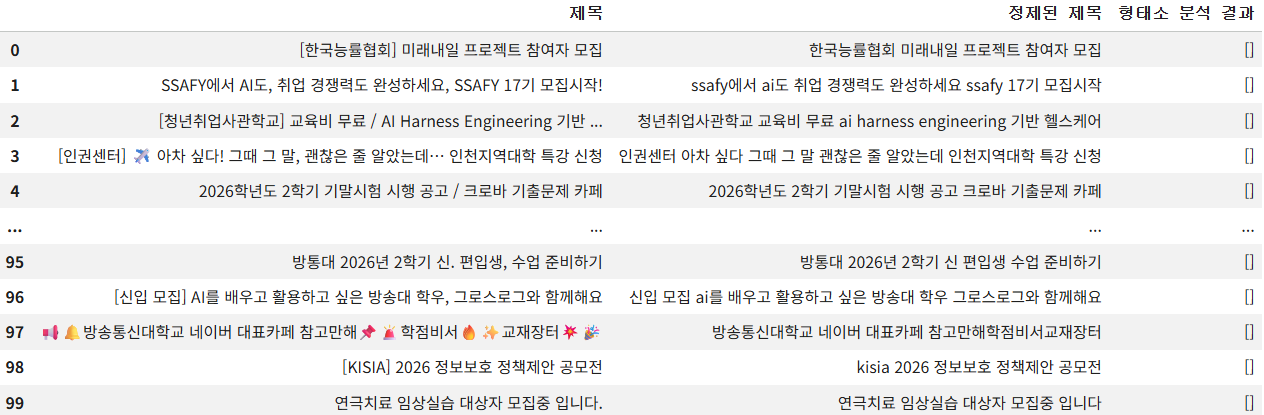

## 13-5 형태소 분석기 설치 및 실행 예시

In [6]:
## Kiwi 형태소 분석기 설치
!pip install kiwipiepy

In [7]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가 (명사로 사용돼야 되는 것들을 사용자 사전으로 추가할 수 있음)
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')

## 문장 형태소 분석 결과 출력
print(kiwi.analyze('안녕하세요 저는 방송대 학생입니다.')[0][0])

[Token(form='안녕', tag='NNG', start=0, len=2), Token(form='하', tag='XSA', start=2, len=1), Token(form='세요', tag='EF', start=3, len=2), Token(form='저', tag='NP', start=6, len=1), Token(form='는', tag='JX', start=7, len=1), Token(form='방송대', tag='NNP', start=9, len=3), Token(form='학생', tag='NNG', start=13, len=2), Token(form='이', tag='VCP', start=15, len=1), Token(form='ᆸ니다', tag='EF', start=15, len=3), Token(form='.', tag='SF', start=18, len=1)]


## 13-6 형태소 분석을 통한 품사 분리

In [8]:
from kiwipiepy import Kiwi

## 형태소 분석기 초기화 및 사용자 사전 추가
kiwi = Kiwi()
kiwi.add_user_word('방송대', 'NNP')
kiwi.add_user_word('방통대', 'NNP')

## 텍스트 형태소 분석 함수
def analyze_morphemes(text):
    if isinstance(text, str):
        result = kiwi.analyze(text)

        morphemes = []
        for token in result[0][0]:
            ## 형태소(form)와 품사(tag) 정보를 튜플로 morphemes에 추가
            morphemes.append((token.form, token.tag))

        return morphemes

    else:
        return []

## 데이터프레임에 형태소 분석 적용 함수
def pos_df(df):
  if not df.empty:
    # `정제된 제목` 칼럼의 값에 analyze_morphemes 함수를 적용하고 결과를 `행태소 분석 결과` 칼럼에 저장
    df['형태소 분석 결과'] = df['정제된 제목'].apply(analyze_morphemes)

## 형태소 분석 적용
pos_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과
0,[한국능률협회] 미래내일 프로젝트 참여자 모집,한국능률협회 미래내일 프로젝트 참여자 모집,"[(한국, NNP), (능률, NNG), (협회, NNG), (미래, NNG), (..."
1,"SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!",ssafy에서 ai도 취업 경쟁력도 완성하세요 ssafy 17기 모집시작,"[(ssafy, SL), (에서, JKB), (ai, SL), (도, JX), (취..."
2,[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 ...,청년취업사관학교 교육비 무료 ai harness engineering 기반 헬스케어,"[(청년, NNG), (취업, NNG), (사관학교, NNG), (교육비, NNG)..."
3,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청,"[(인권, NNG), (센터, NNG), (아차, IC), (싶, VX), (다, ..."
4,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (..."
...,...,...,...
85,"방통대 2026년 2학기 신. 편입생, 수업 준비하기",방통대 2026년 2학기 신 편입생 수업 준비하기,"[(방통대, NNP), (2026, SN), (년, NNB), (2, SN), (학..."
86,"[신입 모집] AI를 배우고 활용하고 싶은 방송대 학우, 그로스로그와 함께해요",신입 모집 ai를 배우고 활용하고 싶은 방송대 학우 그로스로그와 함께해요,"[(신입, NNG), (모집, NNG), (ai, SL), (를, JKO), (배우..."
87,📢🔔방송통신대학교 네이버 대표카페 참고만해📌🚨학점비서🔥✨교재장터💥🎉,방송통신대학교 네이버 대표카페 참고만해학점비서교재장터,"[(방송, NNG), (통신, NNG), (대, XPN), (학교, NNG), (네..."
88,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전,"[(kisia, SL), (2026, SN), (정보, NNG), (보호, NNG)..."


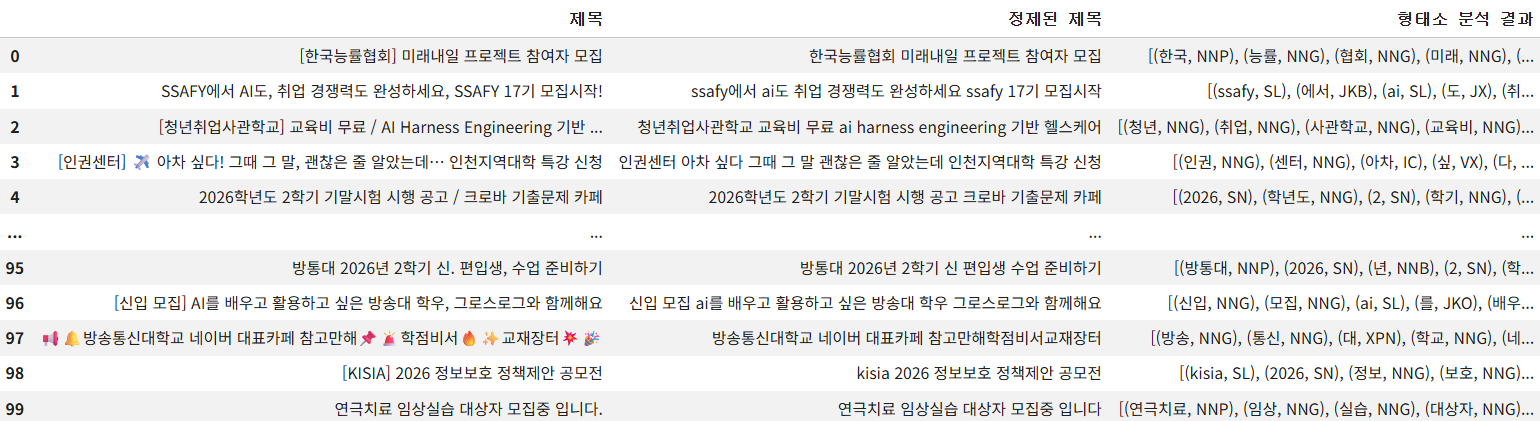

## 13-7 명사 추출

In [9]:
## 형태소 분석 결과에서 명사 추출
def extract_nouns(morphemes):
  # 형태소가 NNG (일반명사), NNP (고유명사) 인 word를 nouns에 저장
  nouns = [word for word, tag in morphemes if tag in ['NNG', 'NNP']]
  return nouns

## 데이터프레임에 명사 추출 적용
def noun_df(df):
  if not df.empty:
      df['명사'] = df['형태소 분석 결과'].apply(extract_nouns)

## 명사 추출 적용
noun_df(cs_df)
cs_df

,제목,정제된 제목,형태소 분석 결과,명사
0,[한국능률협회] 미래내일 프로젝트 참여자 모집,한국능률협회 미래내일 프로젝트 참여자 모집,"[(한국, NNP), (능률, NNG), (협회, NNG), (미래, NNG), (...","[한국, 능률, 협회, 미래, 내일, 프로젝트, 참여자, 모집]"
1,"SSAFY에서 AI도, 취업 경쟁력도 완성하세요, SSAFY 17기 모집시작!",ssafy에서 ai도 취업 경쟁력도 완성하세요 ssafy 17기 모집시작,"[(ssafy, SL), (에서, JKB), (ai, SL), (도, JX), (취...","[취업, 경쟁력, 완성, 기, 모집, 시작]"
2,[청년취업사관학교] 교육비 무료 / AI Harness Engineering 기반 ...,청년취업사관학교 교육비 무료 ai harness engineering 기반 헬스케어,"[(청년, NNG), (취업, NNG), (사관학교, NNG), (교육비, NNG)...","[청년, 취업, 사관학교, 교육비, 무료, 기반, 헬스케어]"
3,"[인권센터] ✈️ 아차 싶다! 그때 그 말, 괜찮은 줄 알았는데… 인천지역대학 특강 신청",인권센터 아차 싶다 그때 그 말 괜찮은 줄 알았는데 인천지역대학 특강 신청,"[(인권, NNG), (센터, NNG), (아차, IC), (싶, VX), (다, ...","[인권, 센터, 그때, 말, 인천, 지역, 대학, 특강, 신청]"
4,2026학년도 2학기 기말시험 시행 공고 / 크로바 기출문제 카페,2026학년도 2학기 기말시험 시행 공고 크로바 기출문제 카페,"[(2026, SN), (학년도, NNG), (2, SN), (학기, NNG), (...","[학년도, 학기, 기말, 시험, 시행, 공고, 크로바, 기출, 문제, 카페]"
...,...,...,...,...
85,"방통대 2026년 2학기 신. 편입생, 수업 준비하기",방통대 2026년 2학기 신 편입생 수업 준비하기,"[(방통대, NNP), (2026, SN), (년, NNB), (2, SN), (학...","[방통대, 학기, 편입, 수업, 준비]"
86,"[신입 모집] AI를 배우고 활용하고 싶은 방송대 학우, 그로스로그와 함께해요",신입 모집 ai를 배우고 활용하고 싶은 방송대 학우 그로스로그와 함께해요,"[(신입, NNG), (모집, NNG), (ai, SL), (를, JKO), (배우...","[신입, 모집, 활용, 방송대, 학우, 그로스로그]"
87,📢🔔방송통신대학교 네이버 대표카페 참고만해📌🚨학점비서🔥✨교재장터💥🎉,방송통신대학교 네이버 대표카페 참고만해학점비서교재장터,"[(방송, NNG), (통신, NNG), (대, XPN), (학교, NNG), (네...","[방송, 통신, 학교, 네이버, 대표, 카페, 참고만해학점비서교재장터]"
88,[KISIA] 2026 정보보호 정책제안 공모전,kisia 2026 정보보호 정책제안 공모전,"[(kisia, SL), (2026, SN), (정보, NNG), (보호, NNG)...","[정보, 보호, 정책, 제안, 공모전]"


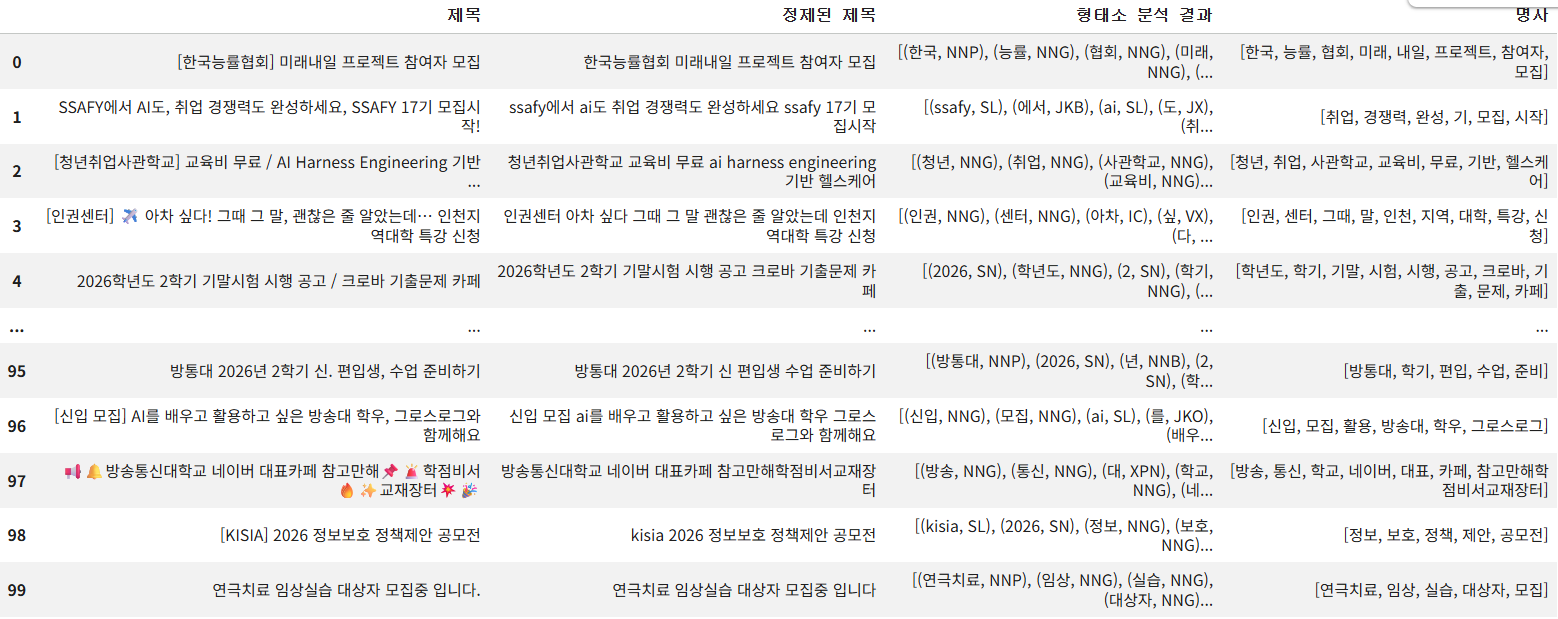

## 13-8 데이터 전처리 통합 함수 정의

In [10]:
## 데이터프레임 전처리 통합 함수
def preprocessing_df(df):
  clean_df(df) ## 텍스트 정제 적용
  pos_df(df) ## 형태소 분석 적용
  noun_df(df) ## 명사 추출 적용

# 3. 키워드 분석

## 13-9 단어 빈도 계산

In [11]:
from collections import Counter

## 데이터프레임에서 단어 빈도 계산
def get_word_count(df):
    if not df.empty:
        # 모든 명사의 리스트를 구함
        all_nouns = df['명사'].sum( )  # 모든 것이 포함된 단일 리스트로 생성

        # 모든 명사들에 대한 Counter 객체(빈도 정보) 를 반환
        return Counter(all_nouns)


## cs_df의 단어 빈도 계산
word_count = get_word_count(cs_df)
print("단어 빈도:")

## 상위 30개 단어(most_common)의 빈도 출력  (가장 많은 순서 (내림차순))
for word, freq in word_count.most_common(30):
    print(f"{word}: {freq}")




단어 빈도:
모집: 36
연극: 28
신입: 23
회원: 21
동아리: 21
기: 16
카페: 14
기출: 12
문제: 12
네이버: 12
방송대: 12
대표: 11
극예술: 10
연구회: 10
정리: 9
참고: 9
요점: 8
극예술연구회: 8
학기: 7
크로바: 6
인터뷰: 6
웹: 6
소설: 6
치료사: 6
전통: 6
교재: 6
장터: 6
공지: 5
온라인: 5
공부: 5


## 13-10 워드클라우드 생성 및 시각화

워드클라우드는 빈도수가 높으면 높을수록 글자의 사이즈가 커지는 것들을 한 곳에 쭉 엮어서 보여주는 형태의 기법이라고 할 수 있다

In [12]:
## WordCloud 라이브러리 설치
!pip install wordcloud

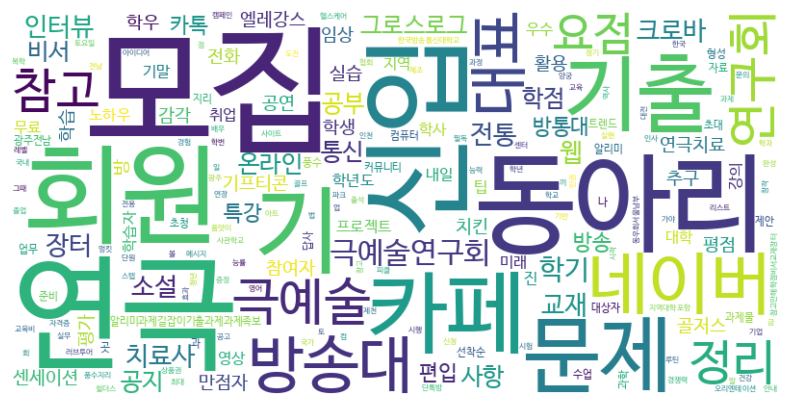

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

## 단어 빈도를 바탕으로 워드클라우드 생성 및 표시
def plot_wordcloud(word_count):
    ## 워드 클라우드 생성
    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis',
        font_path='/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf' ## 한글 폰트 경로 지정
        ).generate_from_frequencies(word_count) # word_count의 빈도 정보를 이용하여 생성

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear') ## 이미지 표시
    plt.axis("off") ## 축 비활성화
    plt.show() ## 그래프 표시

## cs_df에서 단어 빈도 계산
word_count = get_word_count(cs_df)
## 워드클라우드 생성 및 표시
plot_wordcloud(word_count)

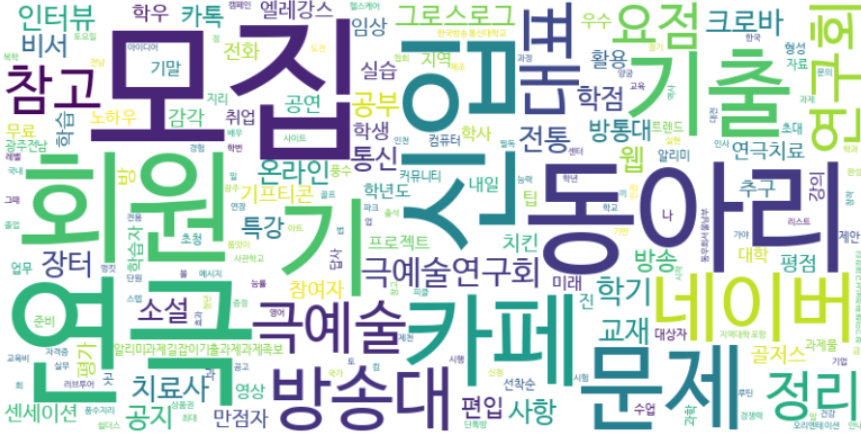

## 13-11 다른 학과의 워드 클라우드 생성

<IPython.core.display.Javascript object>

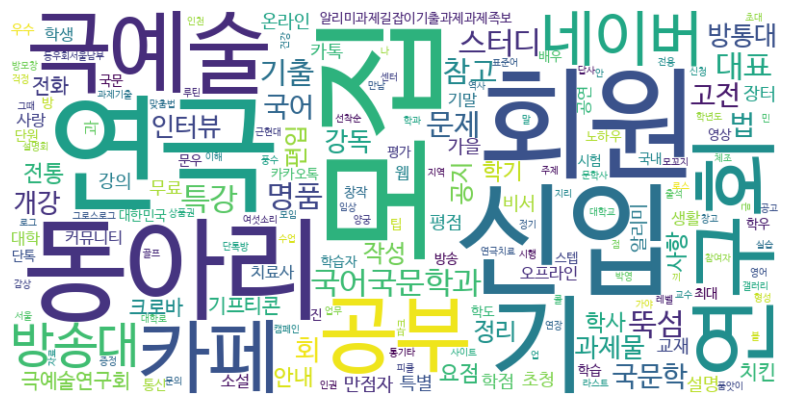

In [14]:
board_name = '국어국문학과'
board_url = 'https://korean.knou.ac.kr/korean/5323/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
ko_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(ko_df)
word_count = get_word_count(ko_df)
plot_wordcloud(word_count)

<IPython.core.display.Javascript object>

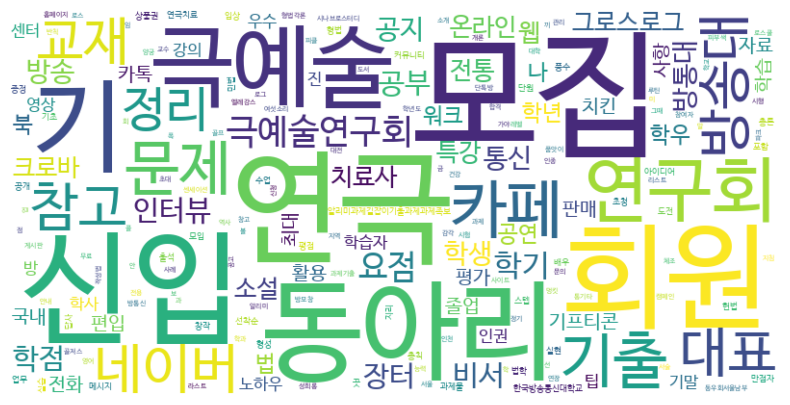

In [15]:
board_name = '법학과'
board_url = 'https://law.knou.ac.kr/law/5176/subview.do'
board_titles = get_board_titles(url=board_url, pages=range(1,11), verbose=False)
law_df = pd.DataFrame(data = {'제목': board_titles})
preprocessing_df(law_df)
word_count = get_word_count(law_df)
plot_wordcloud(word_count)

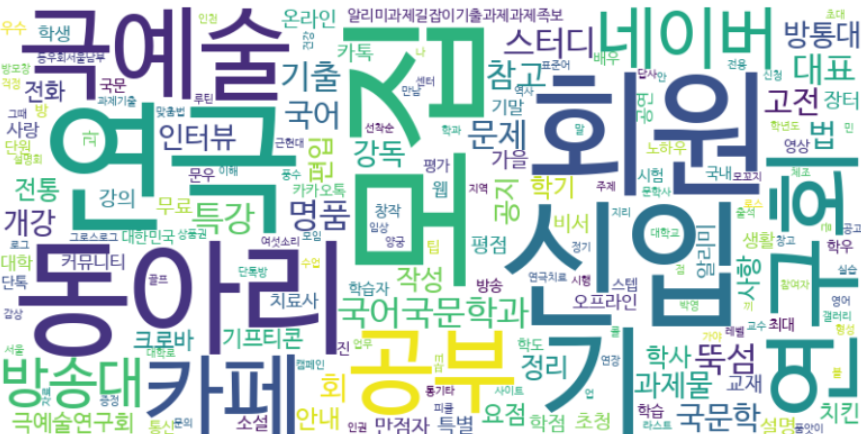




# 4. 텍스트 분류 및 시각화

## 13-12 VLLM 라이브러리 설치 및 LLM 모델 로드

주의
- 런타임 유형 : GPU
- 라이브러리 설치 및 모델 다운로드에 수 분(>6분)의 시간이 소요됩니다.


VLLM 에는 LLM 이라는 객체가 있다.
웹상에 공개돼 있는 LLM들을 가져와서 GPU 상에 올려서 사용할 수 있게 도와주는 라이브러리이다.

기존에 텐서플로우나 파이토치를 사용하는 것보다 훨씬 효율적이고 더 빠른 계산을 도와준다.

In [19]:
from vllm import LLM

## LLM 모델 로드 및 설정
llm = LLM(
    model="LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct",
    tensor_parallel_size=1,
    dtype="half",
    gpu_memory_utilization=0.9,
    trust_remote_code=True  # 커스텀 코드 실행 허용
)

(MainProcess pid=2843) INFO 10-29 07:38:34 [api_utils.py:286] non-default args: {'trust_remote_code': True, 'dtype': 'half', 'gpu_memory_utilization': 0.9, 'disable_log_stats': True, 'model': 'LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct'}


configuration_exaone.py:   0%|          | 0.00/11.3k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/LGAI-EXAONE/EXAONE-3.5-2.4B-Instruct:
- configuration_exaone.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


(MainProcess pid=2843) INFO 10-29 07:38:55 [model.py:733] Resolved architecture: ExaoneForCausalLM
(MainProcess pid=2843) INFO 10-29 07:38:55 [model.py:2495] Downcasting torch.float32 to torch.float16.
(MainProcess pid=2843) INFO 10-29 07:38:55 [model.py:2152] Using max model len 32768
(MainProcess pid=2843) INFO 10-29 07:38:55 [scheduler.py:307] Chunked prefill is enabled with max_num_batched_tokens=8192.


model.safetensors.index.json:   0%|          | 0.00/22.2k [00:00<?, ?B/s]

...

(EngineCore pid=8023) INFO 10-29 07:42:28 [backends.py:398] [backbone] Compiling a graph for compile range (1, 8192) takes 10.73 s
(EngineCore pid=8023) INFO 10-29 07:42:32 [backends.py:927] collected artifacts: 31 entries, 3 artifacts, 4605406 bytes total
(EngineCore pid=8023) INFO 10-29 07:42:32 [decorators.py:743] [backbone] saved AOT compiled function to /root/.cache/vllm/torch_compile_cache/torch_aot_compile/ef64810fe1ca5bcbfba53dd9d29f290f835aa61f5fac56f23713864c030d930c/rank_0_0/model
(EngineCore pid=8023) INFO 10-29 07:42:32 [monitor.py:62] [backbone] torch.compile took 23.35 s in total
(EngineCore pid=8023) INFO 10-29 07:42:32 [monitor.py:91] [backbone] Initial profiling/warmup run took 0.19 s


Capturing CUDA graphs (FULL): 100%|██████████| 2/2 [00:00<00:00,  6.77it/s]


(EngineCore pid=8023) INFO 10-29 07:42:48 [model_runner.py:1127] Graph capturing finished in 12 secs, took 0.31 GiB
(EngineCore pid=8023) INFO 10-29 07:42:49 [gpu_worker.py:759] Available KV cache memory: 7.41 GiB
(EngineCore pid=8023) INFO 10-29 07:42:49 [gpu_worker.py:774] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9000 is equivalent to --gpu-memory-utilization=0.8749 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9251. To disable, set VLLM_MEMORY_PROFILER_ESTIMATE_CUDAGRAPHS=0.
(EngineCore pid=8023) INFO 10-29 07:42:49 [kv_cache_utils.py:2327] GPU KV cache size: 103,552 tokens, Maximum concurrency for 32,768 tokens per request: 3.16x
(EngineCore pid=8023) INFO 10-29 07:42:49 [kernel_warmup.py:176] JIT kernel warmup starting.
(EngineCore pid=8023) INFO 10-29 07:42:49 [kernel_warmup.py:189] JIT kernel warmup finished in 0.00s.


Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:02<00:00, 14.65it/s]


(EngineCore pid=8023) INFO 10-29 07:43:22 [model_runner.py:1127] Graph capturing finished in 9 secs, took 0.19 GiB
(EngineCore pid=8023) INFO 10-29 07:43:22 [gpu_worker.py:971] CUDA graph pool memory: 0.19 GiB (actual), 0.37 GiB (estimated), difference: 0.18 GiB (96.8%).
(EngineCore pid=8023) INFO 10-29 07:43:22 [gpu_worker.py:1034] Free memory on device (14.46/14.56 GiB) on startup. Desired GPU memory utilization is (0.9, 13.11 GiB). Actual usage is 4.78 GiB for consumed memory (weights + non-torch), 0.92 GiB for peak activation, and 0.19 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=7597459764` (7.08 GiB) to fit into requested memory, or `--kv-cache-memory=9051198976` (8.43 GiB) to fully utilize gpu memory. Current kv cache memory in use is 7.41 GiB.
(EngineCore pid=8023) INFO 10-29 07:43:23 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=8023) INFO 10-29 07:43:

## 13-13 LLM 샘플링 파라미터 설정 및 프롬프트 생성

In [24]:
from vllm import SamplingParams ## SamplingParams 클래스 임포트

## 샘플링 파라미터 설정
sampling_params = SamplingParams(
    temperature=0.3, ## 생성 텍스트의 다양성 조절
    top_p=1.0, ## top_p 누적 확률 내에서 토큰 샘플링
    max_tokens=512, ## 생성될 최대 토큰 수
    frequency_penalty=0.5 ## 자주 나타나는 토큰에 대한 패널티
)

def format_prompt(user_input: str) -> str:
    ## 프롬프트 형식화 함수
    messages = [
        # 시스템 메시지 추가
        {'role': 'system', 'content': 'You are EXAONE model from LG AI Research, a helpful assistant.'},

        # 사용자 메시지 추가
        {'role': 'user', 'content': user_input}
    ]
    return messages

## 프롬프트 생성
prompt = format_prompt("대한민국의 수도는 어디인가요? 수도에 여행하러간다면 어떤 즐길거리가 있을까요?")

## LLM을 사용하여 텍스트 생성
# chat 함수를 이용 (프롬프트와 샘플링 파라미터)
outputs = llm.chat(prompt, sampling_params)

## 생성된 텍스트 출력
print("\n생성된 텍스트:", outputs[0].outputs[0].text)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:08<00:00,  8.31s/it, est. speed input: 6.86 toks/s, output: 39.00 toks/s]


생성된 텍스트: 대한민국의 수도는 **서울**입니다. 서울은 역사와 현대가 공존하는 매력적인 도시로, 다양한 관광 명소와 즐길거리를 제공합니다:

1. **경복궁**: 조선 시대의 궁궐로, 아름다운 건축물과 정원을 감상할 수 있습니다. 특히 봄에는 벚꽃이 만발해 아름다운 풍경을 선사합니다.

2. **인사이트 타워**: 서울스카이에서 제공하는 전망대에서 서울의 전경을 한눈에 볼 수 있습니다. 야간에는 특별한 조명으로 더욱 멋진 경치를 즐길 수 있습니다.

3. **한강공원**: 한강을 따라 펼쳐진 넓은 공원에서 산책하거나 자전거 타기를 즐길 수 있습니다. 특히 가을에는 단풍이 아름다워 사진 촬영 명소로 인기가 많습니다.

4. **국립중앙박물관**: 한국의 역사와 문화를 체험할 수 있는 곳으로, 다양한 유물과 전시물을 관람할 수 있습니다.

5. **명동 및 강남 지역**: 쇼핑과 엔터테인먼트의 중심지로, 다양한 쇼핑몰과 카페, 레스토랑이 즐비합니다. 특히 크리스마스 시즌에는 명동 거리가 화려한 장식으로 꾸며집니다.

6. **북촌 한옥마을**: 전통 한옥들이 잘 보존된 지역으로, 고즈넉한 분위기 속에서 한국 전통 문화를 체험할 수 있습니다. 저녁이면 조명이 더해져 특별한 분위기를 느낄 수 있습니다.

이러한 장소들은 서울 여행의 핵심적인 포인트로, 역사와 현대가 어우러진 매력적인 경험을 선사할 것입니다!


## 13-14 LLM 기반 분류 프롬프트 및 함수 정의

In [25]:
## 분류 프롬프트 형식화 함수
def format_classifier_prompt(board_title, title) -> str:
    messages = [
        {"role": "system", "content": "You are EXAONE model from LG AI Research, a helpful assistant."},
        {"role": "user", "content": """주어진 글의 제목을 분류하는 AI 모델입니다.
분류 클래스는 학사/전공, 학생활동, 외부정보로 나뉘어집니다.
- 학사/전공: 교재, 과제, 시험 등 학업 및 전공 관련 내용
- 학생활동: 동아리, 스터디, 모임 등 학생들의 자발적 활동
- 외부정보: 취업, 공모전, 행사 등 외부 정보"""},
        {"role": "user", "content": """예시)
전공명: 컴퓨터학과, 제목: 프로그래밍 과제 질문 -> 학사/전공
전공명: 컴퓨터학과, 제목: 알고리즘 스터디 모집 -> 학생활동
전공명: 컴퓨터학과, 제목: IT 취업 박람회 -> 외부정보"""},
        {"role": "user", "content": f"전공명: {board_title}\n제목: {title}"}
    ]
    return messages

## 분류 수행 함수
def classify(major, title):
    prompt = format_classifier_prompt(major, title) ## 분류 프롬프트 생성
    outputs = llm.chat([prompt], sampling_params) ## LLM으로 분류 실행
    return outputs[0].outputs[0].text ## 분류 결과 텍스트 반환

In [26]:
classify('컴퓨터학과', '딥러닝 개발 중에 질문 있습니다.')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.81s/it, est. speed input: 107.35 toks/s, output: 40.95 toks/s]


'제목: **딥러닝 개발 중에 질문 있습니다.**\n\n**분류:** 학사/전공\n\n**설명:** 이 제목은 딥러닝이라는 특정 학문 분야의 기술적인 내용과 관련된 질문을 다루고 있어 학업 및 전공 관련 내용에 해당하므로 **학사/전공** 분류에 속합니다.'

In [27]:
classify('컴퓨터학과', '연극 동아리 회원 모집!! 신규 단원 혜택! AI로 배우는 연극!')

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.55s/it, est. speed input: 128.41 toks/s, output: 41.94 toks/s]


'**분류 결과:** 학생활동  \n**설명:** 제목이 연극 동아리의 회원 모집과 관련된 내용을 다루고 있으며, 특히 "AI로 배우는 연극!" 부분은 학생들의 자발적인 활동과 관련된 요소를 포함하고 있어 학생활동 분류에 적합합니다.'

## 13-15 분류 결과 파싱 함수 정의

In [28]:
def get_class(analysis_result):
    ## 분석 결과에서 분류 클래스 추출
    classes = ['학사/전공', '학생활동', '외부정보', '기타']
    classes_index = [analysis_result.find(cls) for cls in classes]

    min_index = float('inf')
    min_class = '기타'

    for i in range(len(classes)):
        current_index = classes_index[i]
        if current_index != -1 and current_index < min_index:
            min_index = current_index
            min_class = classes[i]

    return min_class

In [29]:
## 컴퓨터과학과 제목 분류 헬퍼 함수 정의
def classify_cs(title):
  return classify('컴퓨터과학과', title)

## '제목' 컬럼에 분류 함수 적용하여 분석 결과 저장
cs_df['class_analysis'] = cs_df['제목'].apply(classify_cs)
## 분석 결과에서 최종 분류 클래스 추출하여 저장
cs_df['class'] = cs_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  4.07it/s, est. speed input: 804.63 toks/s, output: 32.84 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.61s/it, est. speed input: 129.14 toks/s, output: 43.46 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.92s/it, est. speed input: 75.69 toks/s, output: 42.81 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.52it/s, est. speed input: 305.33 toks/s, output: 42.74 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.15s/it, est. speed input: 90.01 toks/s, output: 43.37 toks/s]


## 13-17 분류 결과 시각화

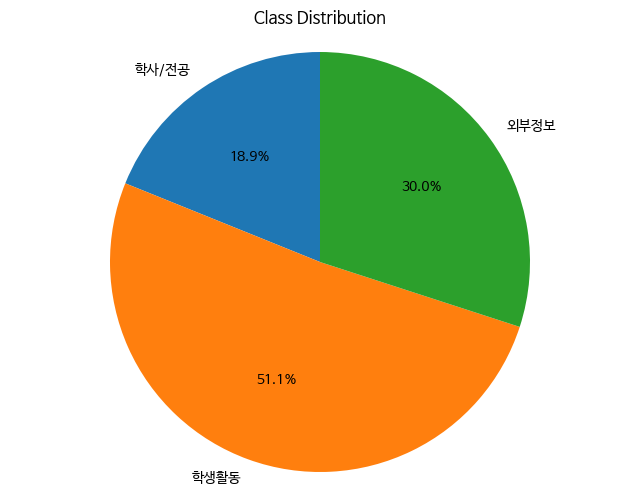

In [30]:
def plot_class(df):
  ## 분류 클래스별 개수 계산 및 순서 재정렬
  class_counts = df['class'].value_counts().reindex(['학사/전공', '학생활동', '외부정보'])

  plt.figure(figsize=(8, 6)) ## 그래프 크기 설정
  plt.pie(class_counts,
          labels=class_counts.index,
          autopct='%.1f%%', ## 퍼센트 표시 형식
          startangle=90, ## 시작 각도 설정
          )

  plt.title('Class Distribution') ## 그래프 제목 설정
  plt.axis('equal') ## 원형 비율 유지
  plt.show() ## 그래프 표시

plot_class(cs_df)

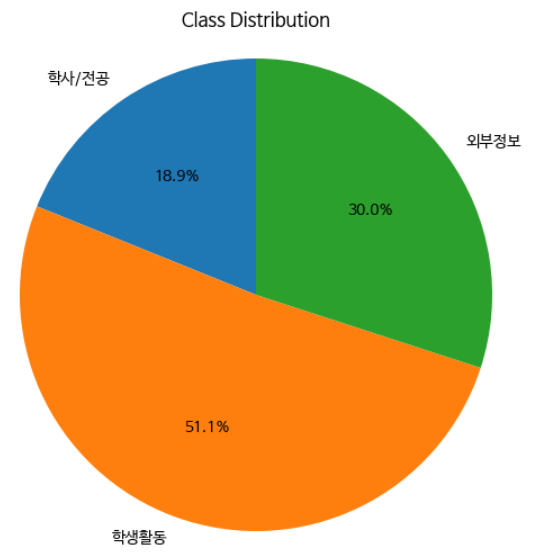

## 13-18 다른 학과의 분류 결과 시각화

In [31]:
def classify_ko(title):
  return classify('국어국문학과', title)

ko_df['class_analysis'] = ko_df['제목'].apply(classify_ko)
ko_df['class'] = ko_df['class_analysis'].apply(get_class)

def classify_law(title):
  return classify('법학과', title)

law_df['class_analysis'] = law_df['제목'].apply(classify_law)
law_df['class'] = law_df['class_analysis'].apply(get_class)

Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.20s/it, est. speed input: 173.26 toks/s, output: 41.65 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.37s/it, est. speed input: 153.68 toks/s, output: 42.97 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

...

Processed prompts: 100%|██████████| 1/1 [00:02<00:00,  2.53s/it, est. speed input: 77.11 toks/s, output: 43.10 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:01<00:00,  1.86s/it, est. speed input: 106.60 toks/s, output: 43.07 toks/s]


Rendering conversations:   0%|          | 0/1 [00:00<?, ?it/s]

Processed prompts: 100%|██████████| 1/1 [00:00<00:00,  1.94it/s, est. speed input: 363.29 toks/s, output: 42.74 toks/s]


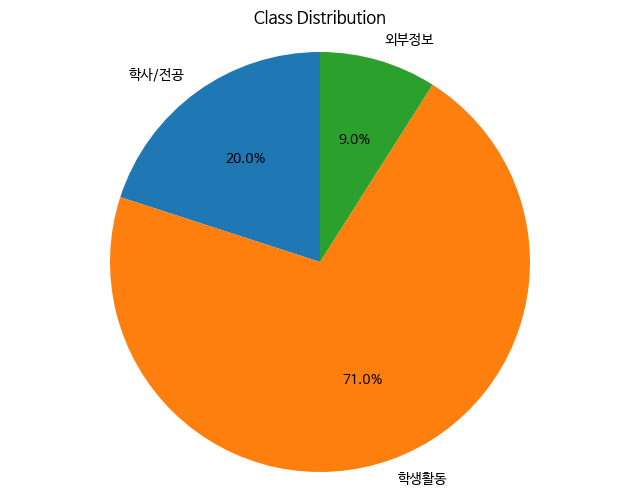

In [32]:
plot_class(ko_df)

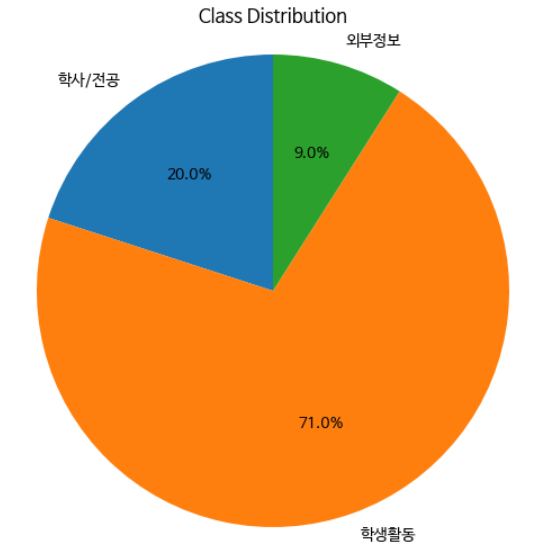

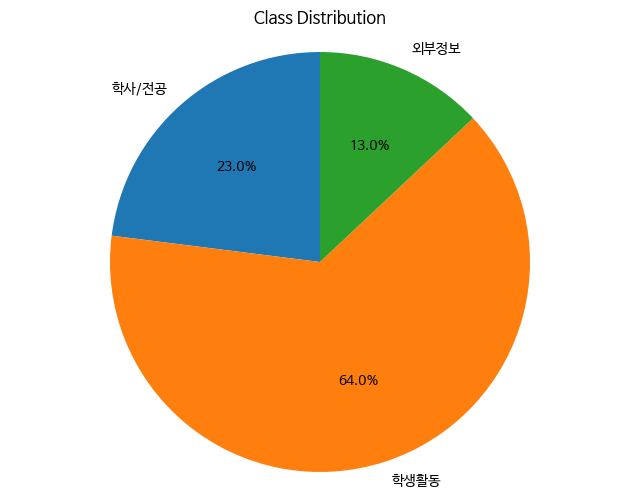

In [33]:
plot_class(law_df)

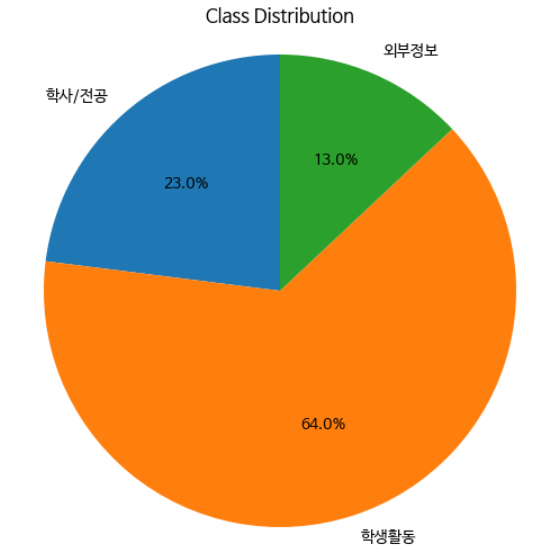